# Citi Field TLC Pickup EDA — Data Inspection and Filtering

This notebook inspects the monthly TLC parquet files, verifies their coverage, and creates a combined Citi Field pickup table using pickup zone 93. The notebook does not yet join Mets events or build event windows.

## 1. Imports and file paths

Because this notebook is stored in `notebooks/`, the parquet folder is one level above it.

In [1]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

DATA_DIR = Path("../high-vol-data")
CITI_FIELD_ZONE = 93
files = sorted(DATA_DIR.glob("*.parquet"))

print("Number of parquet files:", len(files))
for file in files:
    print(file.name)

if not files:
    raise FileNotFoundError(f"No parquet files found in {DATA_DIR.resolve()}")

Number of parquet files: 12
fhvhv_tripdata_2024-01.parquet
fhvhv_tripdata_2024-02.parquet
fhvhv_tripdata_2024-03.parquet
fhvhv_tripdata_2024-04.parquet
fhvhv_tripdata_2024-05.parquet
fhvhv_tripdata_2024-06.parquet
fhvhv_tripdata_2024-07.parquet
fhvhv_tripdata_2024-08.parquet
fhvhv_tripdata_2024-09.parquet
fhvhv_tripdata_2024-10.parquet
fhvhv_tripdata_2024-11.parquet
fhvhv_tripdata_2024-12.parquet


## 2. Inspect one file

This confirms the available fields and data types before processing every month.

In [2]:
sample_file = files[0]
table = pq.ParquetFile(sample_file)

print("Columns:")
print(table.schema.names)

sample = pd.read_parquet(
    sample_file,
    columns=["pickup_datetime", "PULocationID", "DOLocationID"]
)

print(sample.head())
print(sample.dtypes)

Columns:
['hvfhs_license_num', 'dispatching_base_num', 'originating_base_num', 'request_datetime', 'on_scene_datetime', 'pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID', 'trip_miles', 'trip_time', 'base_passenger_fare', 'tolls', 'bcf', 'sales_tax', 'congestion_surcharge', 'airport_fee', 'tips', 'driver_pay', 'shared_request_flag', 'shared_match_flag', 'access_a_ride_flag', 'wav_request_flag', 'wav_match_flag']
      pickup_datetime  PULocationID  DOLocationID
0 2024-01-01 00:28:08           161           158
1 2024-01-01 00:12:53           137            79
2 2024-01-01 00:23:05            79           186
3 2024-01-01 00:41:04           234           148
4 2024-01-01 00:57:21           148            97
pickup_datetime    datetime64[us]
PULocationID                int32
DOLocationID                int32
dtype: object


## 3. Check monthly coverage and timestamp quality

In [3]:
monthly_checks = []

for file in files:
    month_df = pd.read_parquet(
        file,
        columns=["pickup_datetime", "PULocationID"]
    )
    month_df["pickup_datetime"] = pd.to_datetime(
        month_df["pickup_datetime"], errors="coerce"
    )
    monthly_checks.append({
        "file": file.name,
        "rows": len(month_df),
        "start": month_df["pickup_datetime"].min(),
        "end": month_df["pickup_datetime"].max(),
        "missing_timestamps": month_df["pickup_datetime"].isna().sum(),
    })

monthly_checks = pd.DataFrame(monthly_checks)
display(monthly_checks)

,file,rows,start,end,missing_timestamps
0,fhvhv_tripdata_2024-01.parquet,19663930,2024-01-01,2024-01-31 23:59:59,0
1,fhvhv_tripdata_2024-02.parquet,19359148,2024-02-01,2024-02-29 23:59:59,0
2,fhvhv_tripdata_2024-03.parquet,21280788,2024-03-01,2024-03-31 23:59:59,0
3,fhvhv_tripdata_2024-04.parquet,19733038,2024-04-01,2024-04-30 23:59:59,0
4,fhvhv_tripdata_2024-05.parquet,20704538,2024-05-01,2024-05-31 23:59:59,0
5,fhvhv_tripdata_2024-06.parquet,20123226,2024-06-01,2024-06-30 23:59:59,0
6,fhvhv_tripdata_2024-07.parquet,19182934,2024-07-01,2024-07-31 23:59:59,0
7,fhvhv_tripdata_2024-08.parquet,19128392,2024-08-01,2024-08-31 23:59:59,0
8,fhvhv_tripdata_2024-09.parquet,19209788,2024-09-01,2024-09-30 23:59:59,0
9,fhvhv_tripdata_2024-10.parquet,20028282,2024-10-01,2024-10-31 23:59:59,0


## 4. Count Citi Field pickups by month

`PULocationID == 93` keeps rides that started in Citi Field's TLC zone.

In [4]:
zone_checks = []

for file in files:
    zone_df = pd.read_parquet(file, columns=["PULocationID"])
    zone_checks.append({
        "file": file.name,
        "citi_field_pickups": (zone_df["PULocationID"] == CITI_FIELD_ZONE).sum(),
    })

zone_checks = pd.DataFrame(zone_checks)
display(zone_checks)

,file,citi_field_pickups
0,fhvhv_tripdata_2024-01.parquet,5350
1,fhvhv_tripdata_2024-02.parquet,5331
2,fhvhv_tripdata_2024-03.parquet,7753
3,fhvhv_tripdata_2024-04.parquet,13167
4,fhvhv_tripdata_2024-05.parquet,21144
5,fhvhv_tripdata_2024-06.parquet,25035
6,fhvhv_tripdata_2024-07.parquet,18814
7,fhvhv_tripdata_2024-08.parquet,34600
8,fhvhv_tripdata_2024-09.parquet,29163
9,fhvhv_tripdata_2024-10.parquet,15247


## Preparing Citi Field Pickup Data

This section will load the monthly TLC parquet files, keep the pickup time and pickup-zone columns, filter the records to Citi Field’s zone, combine the monthly data, and count pickups in 15-minute intervals. This creates the pickup dataset that will later be matched with Mets game events.

In [5]:
chunks = []

for file in files:
    month_df = pd.read_parquet(
        file,
        columns=["pickup_datetime", "PULocationID"]
    )
    month_df["pickup_datetime"] = pd.to_datetime(
        month_df["pickup_datetime"], errors="coerce"
    )
    month_df = month_df[
        (month_df["PULocationID"] == CITI_FIELD_ZONE)
        & month_df["pickup_datetime"].notna()
    ].copy()
    chunks.append(month_df)

citi_trips = pd.concat(chunks, ignore_index=True)

print("Citi Field pickups:", len(citi_trips))
display(citi_trips.head())

Citi Field pickups: 192516


,pickup_datetime,PULocationID
0,2024-01-01 00:41:28,93
1,2024-01-01 00:49:03,93
2,2024-01-01 00:43:59,93
3,2024-01-01 00:36:07,93
4,2024-01-01 00:55:25,93


## 6. Create 15-minute pickup counts

Each individual pickup is assigned to the 15-minute interval in which it began.

In [6]:
citi_trips["time_bin"] = citi_trips["pickup_datetime"].dt.floor("15min")

pickup_counts = (
    citi_trips
    .groupby("time_bin")
    .size()
    .reset_index(name="pickup_count")
    .sort_values("time_bin")
)

display(pickup_counts.head())
display(pickup_counts.sort_values("pickup_count", ascending=False).head(10))

,time_bin,pickup_count
0,2024-01-01 00:00:00,5
1,2024-01-01 00:15:00,1
2,2024-01-01 00:30:00,10
3,2024-01-01 00:45:00,8
4,2024-01-01 01:00:00,5


,time_bin,pickup_count
18492,2024-09-05 00:30:00,162
14824,2024-07-21 23:00:00,160
14648,2024-07-19 23:15:00,159
9315,2024-05-13 22:45:00,158
11453,2024-06-09 22:45:00,154
18415,2024-09-04 00:30:00,153
17909,2024-08-28 23:45:00,152
12747,2024-06-25 22:45:00,151
9399,2024-05-14 23:15:00,150
21855,2024-10-16 23:00:00,149


## 7. Check for Missing Values


In [7]:
events_file = Path("../citi_field_events_2024.csv")
events = pd.read_csv(events_file)

missing_by_column = events.isna().sum()
print("Missing values by column:")
display(missing_by_column)
print("Total missing entries:", int(missing_by_column.sum()))

Missing values by column:


event_id            0
event_date          0
venue               0
venue_zone_id       0
opponent            0
start_time_local    0
duration_minutes    0
mlb_game_id         0
end_time_local      0
dtype: int64

Total missing entries: 0


## 8. Prepare Event Time Ranges

This section converts the event start and end times into timezone-aware datetimes, checks that the event records are valid, and creates an event window from 30 minutes before each game starts to 90 minutes after it ends. These ranges will be used to match Citi Field pickup intervals to Mets games.

In [8]:
events_prepared = events.copy()

events_prepared["start_time_dt"] = pd.to_datetime(
    events_prepared["start_time_local"], utc=True, errors="coerce"
)
events_prepared["end_time_dt"] = pd.to_datetime(
    events_prepared["end_time_local"], utc=True, errors="coerce"
)

invalid_times = (
    events_prepared["start_time_dt"].isna()
    | events_prepared["end_time_dt"].isna()
    | (events_prepared["end_time_dt"] <= events_prepared["start_time_dt"])
)
duplicate_ids = events_prepared["event_id"].duplicated().sum()
wrong_venue = (events_prepared["venue"] != "Citi Field").sum()

print("Invalid or reversed time ranges:", int(invalid_times.sum()))
print("Duplicate event IDs:", int(duplicate_ids))
print("Events outside Citi Field:", int(wrong_venue))

events_prepared["window_start"] = events_prepared["start_time_dt"] - pd.Timedelta(minutes=30)
events_prepared["window_end"] = events_prepared["end_time_dt"] + pd.Timedelta(minutes=90)

display(
    events_prepared[
        ["event_id", "event_date", "opponent", "start_time_dt",
         "end_time_dt", "window_start", "window_end"]
    ].head()
)

Invalid or reversed time ranges: 0
Duplicate event IDs: 0
Events outside Citi Field: 0


,event_id,event_date,opponent,start_time_dt,end_time_dt,window_start,window_end
0,METS_20240329_745848,2024-03-29,Milwaukee Brewers,2024-03-29 17:40:00+00:00,2024-03-29 20:08:00+00:00,2024-03-29 17:10:00+00:00,2024-03-29 21:38:00+00:00
1,METS_20240330_745850,2024-03-30,Milwaukee Brewers,2024-03-30 17:40:00+00:00,2024-03-30 20:30:00+00:00,2024-03-30 17:10:00+00:00,2024-03-30 22:00:00+00:00
2,METS_20240331_745845,2024-03-31,Milwaukee Brewers,2024-03-31 17:40:00+00:00,2024-03-31 20:23:00+00:00,2024-03-31 17:10:00+00:00,2024-03-31 21:53:00+00:00
3,METS_20240401_745842,2024-04-01,Detroit Tigers,2024-04-01 23:10:00+00:00,2024-04-02 01:56:00+00:00,2024-04-01 22:40:00+00:00,2024-04-02 03:26:00+00:00
4,METS_20240404_745843,2024-04-04,Detroit Tigers,2024-04-04 16:15:00+00:00,2024-04-04 18:38:00+00:00,2024-04-04 15:45:00+00:00,2024-04-04 20:08:00+00:00


## 9. Match Pickup Counts to Events

This section compares each 15-minute pickup interval with the prepared Mets game times. Intervals are labeled `before_game` if they fall within the 30 minutes before first pitch, `during_game` from start through end, `after_game` within 90 minutes after the game, or `no_event` otherwise. Matched intervals retain the event ID, game date, and opponent.

In [9]:
pickup_event_matches = pickup_counts.copy()

# TLC pickup timestamps are local New York times. Convert them to the same
# timezone-aware representation used by the event timestamps.
pickup_event_matches["pickup_time_dt"] = (
    pd.to_datetime(pickup_event_matches["time_bin"], errors="coerce")
    .dt.tz_localize("America/New_York", ambiguous="NaT", nonexistent="NaT")
)

pickup_event_matches["event_id"] = pd.NA
pickup_event_matches["event_date"] = pd.NA
pickup_event_matches["opponent"] = pd.NA
pickup_event_matches["event_phase"] = "no_event"

# Assign the most specific phase first. This prevents an overlapping event
# window from replacing an already assigned game interval.
for phase, start_column, end_column in [
    ("during_game", "start_time_dt", "end_time_dt"),
    ("before_game", "window_start", "start_time_dt"),
    ("after_game", "end_time_dt", "window_end"),
]:
    for _, event in events_prepared.iterrows():
        in_phase = (
            (pickup_event_matches["pickup_time_dt"] >= event[start_column])
            & (pickup_event_matches["pickup_time_dt"] < event[end_column])
            & pickup_event_matches["event_phase"].eq("no_event")
        )
        pickup_event_matches.loc[in_phase, "event_id"] = event["event_id"]
        pickup_event_matches.loc[in_phase, "event_date"] = event["event_date"]
        pickup_event_matches.loc[in_phase, "opponent"] = event["opponent"]
        pickup_event_matches.loc[in_phase, "event_phase"] = phase

print("Pickup intervals by event phase:")
display(pickup_event_matches["event_phase"].value_counts())
display(
    pickup_event_matches[
        ["time_bin", "pickup_count", "event_id", "event_date",
         "opponent", "event_phase"]
    ].query("event_phase != 'no_event'").head(10)
)

Pickup intervals by event phase:


event_phase
no_event       26153
during_game      923
after_game       498
before_game      166
Name: count, dtype: int64

,time_bin,pickup_count,event_id,event_date,opponent,event_phase
5922,2024-03-29 13:15:00,5,METS_20240329_745848,2024-03-29,Milwaukee Brewers,before_game
5923,2024-03-29 13:30:00,1,METS_20240329_745848,2024-03-29,Milwaukee Brewers,before_game
5924,2024-03-29 13:45:00,7,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
5925,2024-03-29 14:00:00,12,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
5926,2024-03-29 14:15:00,7,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
5927,2024-03-29 14:30:00,4,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
5928,2024-03-29 14:45:00,8,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
5929,2024-03-29 15:00:00,13,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
5930,2024-03-29 15:15:00,14,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game
5931,2024-03-29 15:30:00,21,METS_20240329_745848,2024-03-29,Milwaukee Brewers,during_game


## 10. Compare Pickup Counts by Game Phase

This section summarizes and compares the observed 15-minute pickup counts before, during, and after Mets games. It reports the average and median for each phase and plots the average counts. Because `pickup_counts` includes only intervals with at least one recorded pickup, these summaries do not include zero-pickup intervals.

Pickup counts by event phase:


,intervals,average_pickups,median_pickups
event_phase,,,
before_game,166,8.02,5.0
during_game,923,22.90,14.0
after_game,498,50.12,44.0


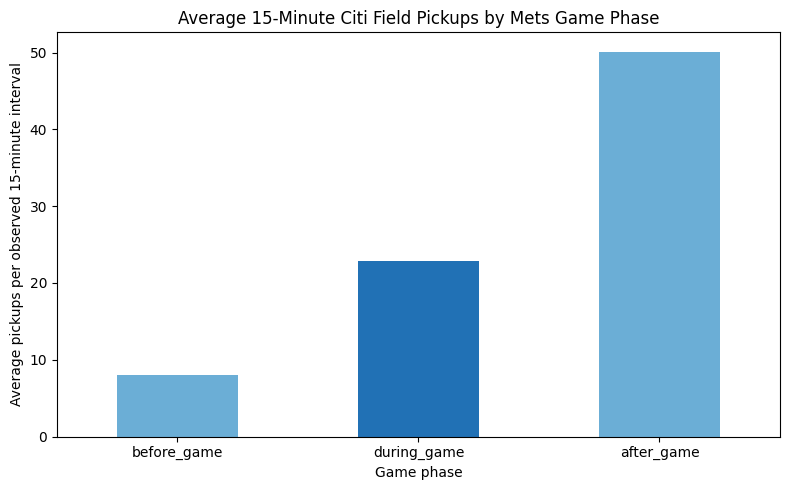

In [10]:
import matplotlib.pyplot as plt

phase_order = ["before_game", "during_game", "after_game"]
game_phase_counts = pickup_event_matches[
    pickup_event_matches["event_phase"].isin(phase_order)
]

phase_summary = (
    game_phase_counts
    .groupby("event_phase")["pickup_count"]
    .agg(intervals="count", average_pickups="mean", median_pickups="median")
    .reindex(phase_order)
)

print("Pickup counts by event phase:")
display(phase_summary.round(2))

ax = phase_summary["average_pickups"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["#6baed6", "#2171b5", "#6baed6"],
    rot=0,
)
ax.set_title("Average 15-Minute Citi Field Pickups by Mets Game Phase")
ax.set_xlabel("Game phase")
ax.set_ylabel("Average pickups per observed 15-minute interval")
plt.tight_layout()
plt.show()